# Nonlinear static analysis

A simply supported rectangular isotropic plate, compressed along $x$ below
its first buckling load and loaded by a transverse force at the centre, so
that it deflects out of plane instead of staying on the flat path. Two
transverse loads are analysed:

1. a small one, for which the response is the linearised one, compared with
   the solution of the linear static problem with the stiffness reduced by
   the geometric stiffness of the axial load;
2. a large one, reaching a deflection of about 2.6 times the thickness,
   where the membrane stretching of the von Kármán strains [1] carries part
   of the load and the plate is stiffer than the linearised prediction.

The same model is checked in `tests/test_static_axial_load_nonlinear.py`.

## Theory

For deflections of the order of the thickness or larger, the equilibrium

$$
\boldsymbol{R}(\boldsymbol{u}, \lambda) =
\boldsymbol{F}_{int}(\boldsymbol{u}) - \lambda \boldsymbol{F}_{ext}
= \boldsymbol{0}
$$

is solved for the displacements at increasing values of the load factor
$\lambda$. Each Newton-Raphson iteration solves

$$
\boldsymbol{K}_T \Delta\boldsymbol{u} = -\boldsymbol{R}, \qquad
\boldsymbol{K}_T = \frac{\partial \boldsymbol{R}}{\partial \boldsymbol{u}}
= \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL}(\boldsymbol{u})
+ \boldsymbol{K}_{GNL}(\boldsymbol{u}) + \boldsymbol{K}_G(\boldsymbol{u})
$$

with all the matrices computed with the current displacements, from
`update_KC0`, `update_KCNL` and `update_KG`, and $\boldsymbol{F}_{int}$
from `update_fint`. Since $\boldsymbol{K}_T$ is the exact Jacobian of
$\boldsymbol{F}_{int}$, the iterations converge quadratically near the
solution: each step squares the residual. With an inconsistent tangent the
residual falls by a roughly constant factor instead.

Below the buckling load, the response to a small transverse load
$\boldsymbol{F}_t$ superposed on the in-plane load $P$ tends to the
linearised solution

$$
\boldsymbol{u}_{lin} = \left( \boldsymbol{K}_{C0} + \boldsymbol{K}_G(P)
\right)^{-1} \boldsymbol{F}_t
$$

with $\boldsymbol{K}_G(P)$ of the static solution of the in-plane load
alone. Its amplification over the response to the transverse load alone,
$\boldsymbol{K}_{C0}^{-1} \boldsymbol{F}_t$, is below the single-mode
ceiling $1/(1 - P/P_{cr})$, $P_{cr}$ the first buckling load, since a point
load excites many modes.

The nonlinear equilibrium is solved with the full Newton-Raphson method of
`structsolve.Analysis`, the tangent stiffness matrix rebuilt at every
iteration, with Crisfield's convergence criterion: the residual and the
reference forces scaled with the diagonal of $\boldsymbol{K}_{C0}$, and the
iterations stop when their ratio $\zeta$ is below `Analysis.relTOL = 1e-9`.

## Model

The plate has $a = 0.9$ m by $b = 0.5$ m, $h = 1$ mm, $E = 70$ GPa and
$\nu = 0.3$, on a mesh of 13 by 7 nodes. The four edges are simply
supported: $w$ and $w_{,y}$ are constrained on the edges $x$ = constant,
$w$ and $w_{,x}$ on the edges $y$ = constant, since along an edge the
interpolated $w$ depends only on $w$ and its derivative along the edge at
the two nodes of the edge. $v$ is constrained on the edges $x = 0$ and
$x = a$, and $u$ on the line $x = a/2$. The element matrices and the
internal forces are integrated with 7 by 7 points (`nint = 7`), which
integrate $\boldsymbol{F}_{int}$ and $\boldsymbol{K}_{CNL}$ exactly. The test
uses the same model and stores the buckling load and the deflections
computed here.

`build_model` creates the elements and $\boldsymbol{K}_{C0}$, and keeps the
value arrays of $\boldsymbol{K}_{CNL} + \boldsymbol{K}_{GNL}$ and
$\boldsymbol{K}_G$, which are zeroed and recomputed at each iteration,
since the update functions add to them.

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh, spsolve
import matplotlib.pyplot as plt

from composites import isotropic_plate
from structsolve import Analysis
from structsolve.convergence import crisfield_weights, crisfield_zeta

from bfscplate2d import (BFSCPlate2D, update_KC0, update_KCNL, update_KG,
        update_fint, DOF, DOUBLE, INT, KC0_SPARSE_SIZE, KCNL_SPARSE_SIZE,
        KG_SPARSE_SIZE)
from bfscplate2d.quadrature import get_points_weights

# number of nodes
nx = 13
ny = 7

# geometry
a = 0.9
b = 0.5

# material properties
E = 0.7e11
nu = 0.3
h = 0.001

In [2]:
class Model(object):
    """Mesh, elements, boundary conditions and the operators built on them."""


def build_model():
    points, weights = get_points_weights(nint=7)
    lam = isotropic_plate(thickness=h, E=E, nu=nu)

    xlin = np.linspace(0, a, nx)
    ylin = np.linspace(0, b, ny)
    xmesh, ymesh = np.meshgrid(xlin, ylin)

    ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
    x = ncoords[:, 0]
    y = ncoords[:, 1]
    nids = 1 + np.arange(ncoords.shape[0])
    nid_pos = dict(zip(nids, np.arange(len(nids))))

    nids_mesh = nids.reshape(nx, ny)
    n1s = nids_mesh[:-1, :-1].flatten()
    n2s = nids_mesh[1:, :-1].flatten()
    n3s = nids_mesh[1:, 1:].flatten()
    n4s = nids_mesh[:-1, 1:].flatten()
    num_elements = len(n1s)

    N = DOF*nx*ny
    KC0r = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0c = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
    KC0v = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KCNLr = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
    KCNLc = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
    KCNLv = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    KGr = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGc = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
    KGv = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
    init_k_KC0 = 0
    init_k_KCNL = 0
    init_k_KG = 0

    elements = []
    for n1, n2, n3, n4 in zip(n1s, n2s, n3s, n4s):
        plate = BFSCPlate2D()
        plate.n1 = n1
        plate.n2 = n2
        plate.n3 = n3
        plate.n4 = n4
        plate.c1 = DOF*nid_pos[n1]
        plate.c2 = DOF*nid_pos[n2]
        plate.c3 = DOF*nid_pos[n3]
        plate.c4 = DOF*nid_pos[n4]
        plate.ABD = lam.ABD
        plate.lex = a/(nx - 1)
        plate.ley = b/(ny - 1)
        plate.init_k_KC0 = init_k_KC0
        plate.init_k_KCNL = init_k_KCNL
        plate.init_k_KG = init_k_KG
        update_KC0(plate, points, weights, KC0r, KC0c, KC0v)
        init_k_KC0 += KC0_SPARSE_SIZE
        init_k_KCNL += KCNL_SPARSE_SIZE
        init_k_KG += KG_SPARSE_SIZE
        elements.append(plate)

    KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

    # simply supported: w and its derivative along the edge
    bk = np.zeros(N, dtype=bool)
    edges_x = isclose(x, 0) | isclose(x, a)
    edges_y = isclose(y, 0) | isclose(y, b)
    bk[6::DOF] = edges_x | edges_y
    bk[8::DOF] = edges_x
    bk[7::DOF] = edges_y
    # in-plane supports
    bk[3::DOF] = edges_x
    bk[0::DOF] = isclose(x, a/2.)
    bu = ~bk

    m = Model()
    m.points, m.weights, m.lam = points, weights, lam
    m.ncoords, m.x, m.y = ncoords, x, y
    m.xmesh, m.ymesh = xmesh, ymesh
    m.nid_pos = nid_pos
    m.elements = elements
    m.N = N
    m.KC0 = KC0
    m.KC0uu = KC0[bu, :][:, bu]
    m.bk, m.bu = bk, bu
    m.KCNLr, m.KCNLc, m.KCNLv = KCNLr, KCNLc, KCNLv
    m.KGr, m.KGc, m.KGv = KGr, KGc, KGv
    return m


def calc_KCNL(m, u):
    """The nonlinear part K_CNL(u) + K_GNL(u) of the tangent."""
    m.KCNLv *= 0
    for plate in m.elements:
        update_KCNL(u, plate, m.points, m.weights, m.KCNLr, m.KCNLc, m.KCNLv)
    return coo_matrix((m.KCNLv, (m.KCNLr, m.KCNLc)),
                      shape=(m.N, m.N)).tocsc()


def calc_KG(m, u):
    """The geometric stiffness K_G(u), of the tangent and of the linearised
    solutions."""
    m.KGv *= 0
    for plate in m.elements:
        update_KG(u, plate, m.points, m.weights, m.KGr, m.KGc, m.KGv)
    return coo_matrix((m.KGv, (m.KGr, m.KGc)), shape=(m.N, m.N)).tocsc()


def calc_fint(m, u):
    fint = np.zeros(m.N)
    for plate in m.elements:
        update_fint(u, plate, m.points, m.weights, fint)
    return fint

The callables of `structsolve.Analysis` work on the unknown degrees of
freedom only: the solution vector of the solver is `c = u[bu]`, and the
force vectors and matrices are restricted to `bu`. `calc_kC` with
`NLgeom=True` returns $\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_{GNL}$ and `calc_kG` returns $\boldsymbol{K}_G$, such that
their sum is $\boldsymbol{K}_T$. `calc_fint` also keeps the load factor and
the internal forces of each iteration, from which the residual history is
computed. `w_field` interpolates $w$ inside the elements for the plots.

In [3]:
class Callables(object):
    """The callables of structsolve.Analysis for the model m under the
    external forces fext."""
    def __init__(self, m, fext):
        self.m = m
        self.fext = fext
        self.iterations = []

    def expand(self, c):
        """The displacements of the model from those of the unknown dofs."""
        u = np.zeros(self.m.N)
        u[self.m.bu] = c
        return u

    def calc_fext(self, inc=1., silent=False):
        return inc*self.fext[self.m.bu]

    def calc_fint(self, c, inc=1., silent=False):
        fint = calc_fint(self.m, self.expand(c))[self.m.bu]
        self.iterations.append((inc, fint))
        return fint

    def calc_kC(self, c=None, NLgeom=False, silent=False):
        if not NLgeom:
            return self.m.KC0uu
        bu = self.m.bu
        KCNL = calc_KCNL(self.m, self.expand(c))
        return (self.m.KC0 + KCNL)[bu, :][:, bu]

    def calc_kG(self, c=None, NLgeom=False, silent=False):
        bu = self.m.bu
        return calc_KG(self.m, self.expand(c))[bu, :][:, bu]

def w_field(plates, u, nx, ny, n=9):
    """The deflection w interpolated with the rows Sw of each element on
    n by n points per element, for the contour plots."""
    lex, ley = plates[0].lex, plates[0].ley
    X = np.linspace(0, (nx - 1)*lex, (nx - 1)*(n - 1) + 1)
    Y = np.linspace(0, (ny - 1)*ley, (ny - 1)*(n - 1) + 1)
    W = np.zeros((Y.size, X.size))
    xis = np.linspace(-1, 1, n)
    for plate in plates:
        ue = np.concatenate([u[c:c + DOF] for c in
                             (plate.c1, plate.c2, plate.c3, plate.c4)])
        pos1 = plate.c1//DOF
        ix0, iy0 = pos1//ny, pos1 % ny
        for i, xi in enumerate(xis):
            for j, eta in enumerate(xis):
                plate.update_Sw(xi, eta)
                W[iy0*(n - 1) + j, ix0*(n - 1) + i] = np.asarray(plate.Sw) @ ue
    Xmesh, Ymesh = np.meshgrid(X, Y)
    return Xmesh, Ymesh, W

## Loads and first buckling load

The axial compression $P = 300$ N is applied as nodal forces along $u$,
$P/n_y$ at each node of the edges $x = 0$ (along $+x$) and $x = a$ (along
$-x$), and the transverse force at the centre node. The first buckling load
$P_{cr}$ comes from the linear buckling problem
$(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} =
\boldsymbol{0}$ with $\boldsymbol{K}_G$ of the static solution
$\boldsymbol{u}_P$ of the axial load alone, the same $\boldsymbol{K}_G(P)$
used by the linearised solutions below.

In [4]:
m = build_model()
print('elements', len(m.elements), ', unknown degrees of freedom', m.bu.sum())

load = 300.  # N
f_axial = np.zeros(m.N)
f_axial[0::DOF][isclose(m.x, 0)] = +load/ny
f_axial[0::DOF][isclose(m.x, a)] = -load/ny
centre = isclose(m.x, a/2) & isclose(m.y, b/2)
f_unit = np.zeros(m.N)   # transverse force of 1 N at the centre
f_unit[6::DOF][centre] = 1.

# static solution of the axial load alone and linear buckling
u_P = np.zeros(m.N)
u_P[m.bu] = spsolve(m.KC0uu, f_axial[m.bu])
KG_P = calc_KG(m, u_P)
KGuu = KG_P[m.bu, :][:, m.bu]
eigvals, _ = eigsh(A=KGuu, k=5, which='SM', M=m.KC0uu, tol=1e-6,
                   sigma=1., mode='cayley')
eigvals = -1./eigvals
load_cr = eigvals[0]*load
print('P_cr = %.3f N, P/P_cr = %.4f' % (load_cr, load/load_cr))

# operators of the linearised solutions
K_lin = (m.KC0 + KG_P)[m.bu, :][:, m.bu]

elements 72 , unknown degrees of freedom 813
P_cr = 501.719 N, P/P_cr = 0.5979


## 1. Small transverse load: the linearised response

A transverse force of 0.01 N, applied with the axial load in one increment
of the load factor. At this deflection the membrane stretching is
negligible, and the nonlinear solution must reproduce the linearised one
$(\boldsymbol{K}_{C0} + \boldsymbol{K}_G(P))^{-1}\boldsymbol{F}_t$, the
reference of this case, while its amplification over the response to the
transverse load alone must lie between 1 and the ceiling $1/(1 - P/P_{cr})$.

In [5]:
transverse = 0.01  # N
ftrans = transverse*f_unit
fext = f_axial + ftrans

callables = Callables(m, fext)
an = Analysis(calc_fext=callables.calc_fext, calc_fint=callables.calc_fint,
              calc_kC=callables.calc_kC, calc_kG=callables.calc_kG)
an.initialInc = 1.
an.maxInc = 1.
increments, cs = an.static(NLgeom=True, silent=True)
print('converged load factors', increments)
u = callables.expand(cs[-1])
w_max = u[6::DOF].max()

# Crisfield's ratio of every iteration
weights_c = crisfield_weights(m.KC0uu)
f = fext[m.bu]
history1 = [(inc, crisfield_zeta(inc*f - fint, inc*f, fint, weights_c))
            for inc, fint in callables.iterations]
print('zeta per iteration:', ', '.join('%.2e' % z for _, z in history1))

# linearised solution and the transverse load alone
u_lin = np.zeros(m.N)
u_lin[m.bu] = spsolve(K_lin, ftrans[m.bu])
w_lin = u_lin[6::DOF].max()
u_bend = np.zeros(m.N)
u_bend[m.bu] = spsolve(m.KC0uu, ftrans[m.bu])
w_bend = u_bend[6::DOF].max()
amplification = w_max/w_bend
ceiling = 1./(1. - load/load_cr)

print()
print('w_max/h = %.4f' % (w_max/h))
print('%-26s %14s %14s %12s' % ('', 'nonlinear', 'reference', 'rel. diff.'))
print('%-26s %14.6e %14.6e %+11.4f%%' % ('w_max vs linearised (m)', w_max,
      w_lin, 100*(w_max - w_lin)/w_lin))
print('%-26s %14.4f %14.4f %12s' % ('amplification vs ceiling',
      amplification, ceiling, 'bound'))

converged load factors [1.0]
zeta per iteration: 4.01e-04, 4.09e-05, 2.78e-12

w_max/h = 0.0111
                                nonlinear      reference   rel. diff.
w_max vs linearised (m)      1.110364e-05   1.110397e-05     -0.0030%
amplification vs ceiling           1.7615         2.4872        bound


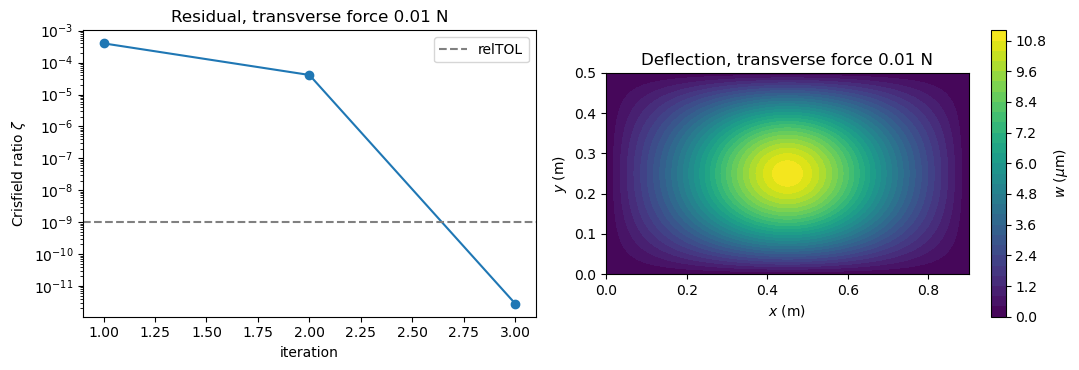

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.semilogy(np.arange(1, len(history1) + 1), [z for _, z in history1], 'o-')
ax.axhline(an.relTOL, color='gray', ls='--', label='relTOL')
ax.set_xlabel('iteration')
ax.set_ylabel(r'Crisfield ratio $\zeta$')
ax.set_title('Residual, transverse force %.2f N' % transverse)
ax.legend()
ax = axes[1]
Xf, Yf, Wf = w_field(m.elements, u, nx, ny)
ax.set_aspect('equal')
c = ax.contourf(Xf, Yf, Wf*1e6, levels=30, cmap='viridis')
fig.colorbar(c, ax=ax, label=r'$w$ ($\mu$m)')
ax.set_xlabel('$x$ (m)')
ax.set_ylabel('$y$ (m)')
ax.set_title('Deflection, transverse force %.2f N' % transverse)
fig.tight_layout()
plt.show()

The plate is at $P/P_{cr} = 0.598$, $P_{cr} = 501.7$ N. Newton-Raphson
converges in one increment: $\zeta$ goes from $4.1 \times 10^{-5}$ to
$2.8 \times 10^{-12}$ in the last step, below the square of the previous
value, the quadratic convergence of a consistent tangent. At $w_{max}/h =
0.011$ the nonlinear deflection, $1.1104 \times 10^{-5}$ m, equals the
linearised one within 0.0030 %. Its amplification over the response to
the transverse force alone, 1.76, lies between 1 and the single-mode
ceiling $1/(1 - P/P_{cr}) = 2.49$.

## 2. Large deflection: membrane stiffening

A transverse force of 5 N, applied with the axial load in four equal
increments of the load factor, $\lambda = 0.25, 0.5, 0.75, 1$, each starting
from the solution of the previous one. At a deflection of the order of the
thickness the membrane stretching carries part of the transverse load, and
the plate comes out stiffer than the linearised prediction
$(\boldsymbol{K}_{C0} + \boldsymbol{K}_G(P))^{-1}\boldsymbol{F}_t$, which
is therefore an upper bound here rather than a reference value. At each
load factor the linearised prediction is $(\boldsymbol{K}_{C0} + \lambda
\boldsymbol{K}_G(P))^{-1} \lambda \boldsymbol{F}_t$, since the axial load
grows with the load factor too.

In [7]:
transverse = 5.  # N
ftrans = transverse*f_unit
fext = f_axial + ftrans

callables = Callables(m, fext)
an = Analysis(calc_fext=callables.calc_fext, calc_fint=callables.calc_fint,
              calc_kC=callables.calc_kC, calc_kG=callables.calc_kG)
an.initialInc = 0.25
an.maxInc = 0.25
increments, cs = an.static(NLgeom=True, silent=True)
print('converged load factors', increments)
u = callables.expand(cs[-1])
w_max = u[6::DOF].max()

f = fext[m.bu]
history2 = [(inc, crisfield_zeta(inc*f - fint, inc*f, fint, weights_c))
            for inc, fint in callables.iterations]
for lbd in increments:
    zs = [z for inc, z in history2 if isclose(inc, lbd)]
    print('lambda = %.2f, zeta per iteration: %s'
          % (lbd, ', '.join('%.2e' % z for z in zs)))

# linearised prediction at each converged load factor
w_nl_inc = [callables.expand(c)[6::DOF].max() for c in cs]
w_lin_inc = []
for lbd in increments:
    u_l = np.zeros(m.N)
    u_l[m.bu] = spsolve((m.KC0 + lbd*KG_P)[m.bu, :][:, m.bu],
                        lbd*ftrans[m.bu])
    w_lin_inc.append(u_l[6::DOF].max())
w_lin = w_lin_inc[-1]

print()
print('%-8s %14s %14s %10s %8s' % ('lambda', 'w_max (m)', 'w_lin (m)',
                                   'ratio', 'w_max/h'))
for lbd, wn, wl in zip(increments, w_nl_inc, w_lin_inc):
    print('%-8.2f %14.6e %14.6e %10.4f %8.3f' % (lbd, wn, wl, wn/wl, wn/h))

converged load factors [0.25, 0.5, 0.75, 1.0]
lambda = 0.25, zeta per iteration: 9.28e-01, 6.05e-03, 9.61e-04, 2.96e-09, 5.51e-15
lambda = 0.50, zeta per iteration: 9.34e-01, 2.59e-02, 4.45e-03, 1.68e-06, 1.51e-11
lambda = 0.75, zeta per iteration: 8.29e-01, 1.66e-02, 2.80e-03, 6.97e-07, 3.56e-12
lambda = 1.00, zeta per iteration: 6.85e-01, 6.49e-03, 5.37e-04, 2.71e-08, 1.06e-14

lambda        w_max (m)      w_lin (m)      ratio  w_max/h
0.25       8.057639e-04   8.814025e-04     0.9142    0.806
0.50       1.497975e-03   2.003327e-03     0.7477    1.498
0.75       2.074973e-03   3.486929e-03     0.5951    2.075
1.00       2.582450e-03   5.551985e-03     0.4651    2.582


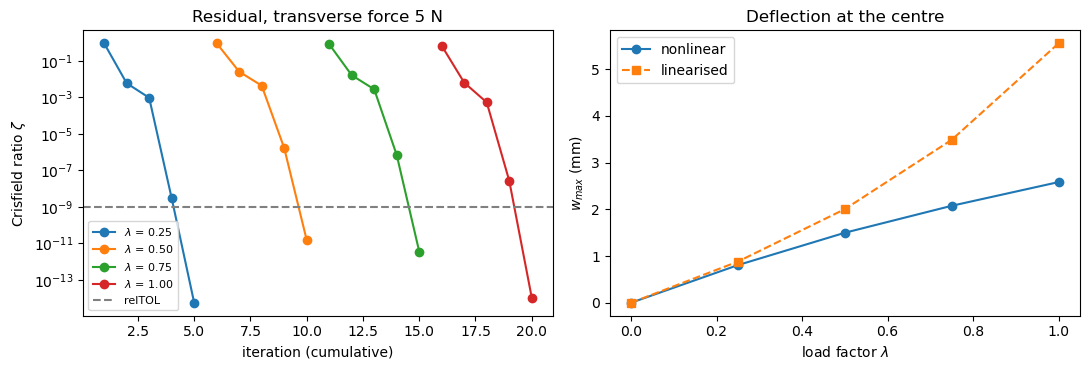

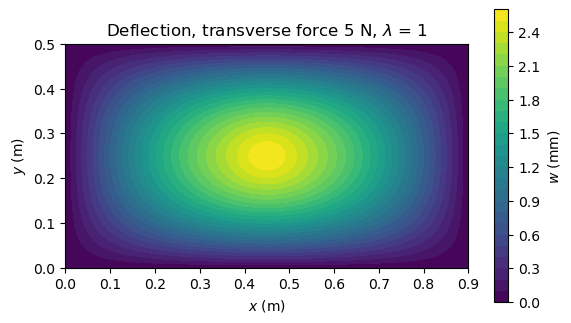

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
k = 1
for lbd in increments:
    zs = [z for inc, z in history2 if isclose(inc, lbd)]
    ax.semilogy(np.arange(k, k + len(zs)), zs, 'o-',
                label=r'$\lambda$ = %.2f' % lbd)
    k += len(zs)
ax.axhline(an.relTOL, color='gray', ls='--', label='relTOL')
ax.set_xlabel('iteration (cumulative)')
ax.set_ylabel(r'Crisfield ratio $\zeta$')
ax.set_title('Residual, transverse force %.0f N' % transverse)
ax.legend(fontsize=8)
ax = axes[1]
lbds = np.concatenate(([0.], increments))
ax.plot(lbds, 1e3*np.concatenate(([0.], w_nl_inc)), 'o-', label='nonlinear')
ax.plot(lbds, 1e3*np.concatenate(([0.], w_lin_inc)), 's--',
        label='linearised')
ax.set_xlabel(r'load factor $\lambda$')
ax.set_ylabel(r'$w_{max}$ (mm)')
ax.set_title('Deflection at the centre')
ax.legend()
fig.tight_layout()
plt.show()

Xf, Yf, Wf = w_field(m.elements, u, nx, ny)
plt.figure(figsize=(6.5, 3.8))
plt.gca().set_aspect('equal')
plt.contourf(Xf, Yf, Wf*1e3, levels=30, cmap='viridis')
plt.colorbar(label='$w$ (mm)')
plt.xlabel('$x$ (m)')
plt.ylabel('$y$ (m)')
plt.title('Deflection, transverse force %.0f N, $\\lambda$ = 1' % transverse)
plt.show()

Each of the four increments converges in five iterations; the last step
takes $\zeta$ from $10^{-6}$ to $10^{-8}$ down to $10^{-11}$ to
$10^{-14}$, the round-off level of the residual, the quadratic convergence
of a consistent tangent. At $\lambda = 1$ the maximum deflection is
$2.582 \times 10^{-3}$ m, $w_{max}/h = 2.58$, 46.5 % of the linearised
prediction $5.552 \times 10^{-3}$ m. The ratio of the two falls from 0.91
at $\lambda = 0.25$, $w_{max}/h = 0.81$, to 0.47 at $\lambda = 1$: the
membrane stretching stiffens the plate as it deflects, and the linearised
solution, which also grows faster as the axial load approaches the buckling
load, overestimates the deflection by a factor of 2.15.

## References

1. Reddy, J. N., *Mechanics of Laminated Composite Plates and Shells: Theory and Analysis*, 2nd ed., CRC Press, Boca Raton, 2003, doi:10.1201/b12409.